## Homework 6

In [14]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt

### Part 1: Practice resampling & chart building with Pandas and Matplotlib

In [2]:
# For this assignment, you'll be working with NYC payroll data again. 
# Import it from wherever you stored the data

payroll_data = pd.read_csv('../pandas/review_pandas_analyses/data/Citywide_Payroll_Data__Fiscal_Year__20240616.csv')
print(len(payroll_data))

552938


Using this data, create an ordered, horizontal bar chart of the top 10 biggest agencies in NYC. 

In [20]:
payroll_data.head()

,Fiscal Year,Payroll Number,Agency Name,Last Name,First Name,Mid Init,Agency Start Date,Work Location Borough,Title Description,Leave Status as of June 30,Base Salary,Pay Basis,Regular Hours,Regular Gross Paid,OT Hours,Total OT Paid,Total Other Pay
0,2023,67,ADMIN FOR CHILDREN'S SVCS,ROODE,SELENA,R,07/22/2019,BRONX,CHILD PROTECTIVE SPECIALIST,ACTIVE,65921.0,per Annum,1820.0,65977.23,6.50,244.34,4400.66
1,2023,67,ADMIN FOR CHILDREN'S SVCS,AARON,TERESA,NaN,03/21/2016,BRONX,CHILD PROTECTIVE SPECIALIST,ACTIVE,65921.0,per Annum,1820.0,65998.30,448.00,22072.10,15938.80
2,2023,67,ADMIN FOR CHILDREN'S SVCS,AARONS,CAMELIA,M,08/08/2016,BROOKLYN,CHILD PROTECTIVE SPECIALIST,ON LEAVE,65921.0,per Annum,602.0,23163.11,28.75,1295.17,8994.61
3,2023,67,ADMIN FOR CHILDREN'S SVCS,ABBASSI,MARIAM,N,11/21/2022,QUEENS,CHILD PROTECTIVE SPECIALIST,ACTIVE,55463.0,per Annum,1050.0,31082.77,27.75,928.43,3115.50
4,2023,67,ADMIN FOR CHILDREN'S SVCS,ABDEL WEDOUD,LASHAWN,NaN,04/24/2023,BROOKLYN,YOUTH DEVELOPMENT SPECIALIST,ACTIVE,50001.0,per Annum,280.0,7792.26,0.00,0.00,0.00


In [44]:
# Your code here.
top10_biggest = payroll_data['Agency Name'].value_counts().head(10).reset_index()
top10_biggest.head()


,Agency Name,count
0,DEPT OF ED PEDAGOGICAL,106882
1,DEPT OF ED PER SESSION TEACHER,82883
2,POLICE DEPARTMENT,58617
3,DEPT OF ED PARA PROFESSIONALS,39580
4,BOARD OF ELECTION POLL WORKERS,29915


<Axes: ylabel='Agency Name'>

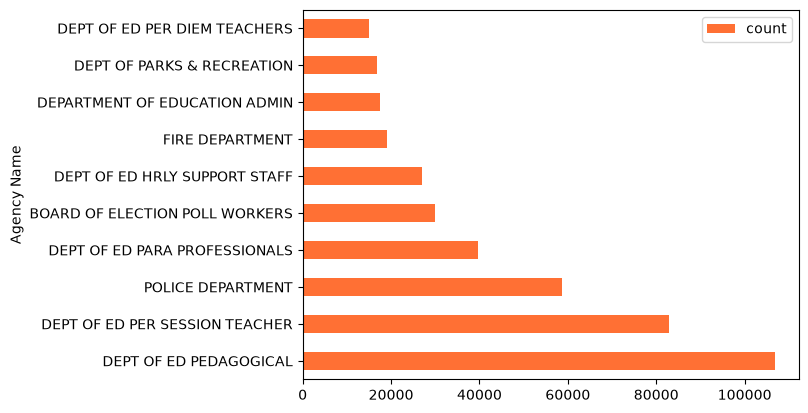

In [45]:
top10_biggest.plot(kind="barh", x="Agency Name", y="count", color="#ff7034")

Now, create an ordered, horizontal bar chart of the top ten agencies with the highest median base salary.

In [28]:
top10_salary = payroll_data.groupby(
    ["Agency Name"]
)["Base Salary"].median().sort_values(ascending=False).head(10).reset_index()

top10_salary.head()

,Agency Name,Base Salary
0,OFFICE OF COLLECTIVE BARGAININ,140000.0
1,FINANCIAL INFO SVCS AGENCY,126952.0
2,BRONX COMMUNITY BOARD #12,115307.0
3,MUNICIPAL WATER FIN AUTHORITY,112604.0
4,DISTRICTING COMMISSION,103750.0


<Axes: ylabel='Agency Name'>

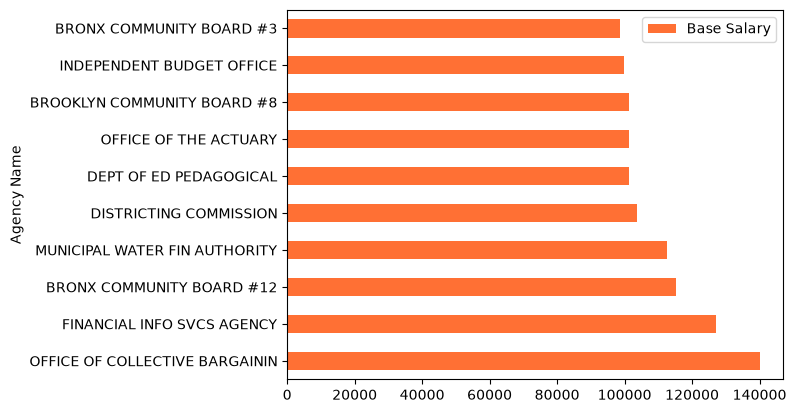

In [31]:
# Your code here.
top10_salary.plot(kind="barh", x="Agency Name", y="Base Salary", color="#ff7034")

Let's return to our police data to practice resampling. 

In [46]:
# Remember to change the file path to match where your data is stored. 

police_data = pd.read_csv("data/fatal-police-shootings-data.csv", parse_dates=["date"])
len(police_data)

10430

In [47]:
police_data.head()

,id,date,threat_type,flee_status,armed_with,city,county,state,latitude,longitude,location_precision,name,age,gender,race,race_source,was_mental_illness_related,body_camera,agency_ids
0,3,2015-01-02,point,not,gun,Shelton,Mason,WA,47.246826,-123.121592,not_available,Tim Elliot,53.0,male,A,not_available,True,False,73
1,4,2015-01-02,point,not,gun,Aloha,Washington,OR,45.487421,-122.891696,not_available,Lewis Lee Lembke,47.0,male,W,not_available,False,False,70
2,5,2015-01-03,move,not,unarmed,Wichita,Sedgwick,KS,37.694766,-97.280554,not_available,John Paul Quintero,23.0,male,H,not_available,False,False,238
3,8,2015-01-04,point,not,replica,San Francisco,San Francisco,CA,37.762910,-122.422001,not_available,Matthew Hoffman,32.0,male,W,not_available,True,False,196
4,9,2015-01-04,point,not,other,Evans,Weld,CO,40.383937,-104.692261,not_available,Michael Rodriguez,39.0,male,H,not_available,False,False,473


Remember in class, we learned that resampling requires several basic steps:

1. Make sure that Pandas is reading in your date column as a date. If it's not, convert it to datetime.
2. Create a new dataframe with your date column as your index
3. Resample the data over the time interval of your choosing.

With this in mind, resample the data over a monthly period and plot it in a line chart.

In [48]:
# Your code here.
police_data.dtypes

id                                     int64
date                          datetime64[us]
threat_type                              str
flee_status                              str
armed_with                               str
city                                     str
county                                   str
state                                    str
latitude                             float64
longitude                            float64
location_precision                       str
name                                     str
age                                  float64
gender                                   str
race                                     str
race_source                              str
was_mental_illness_related              bool
body_camera                             bool
agency_ids                               str
dtype: object

Now create an ordered bar chart of total police killings by year. Put the two charts side by side using the strategy we reviewed in class.

In [37]:
police_data_over_time = police_data.set_index("date")

In [38]:
shootings_tally = police_data_over_time.resample('ME')['id'].count()


date
2015-12-31    995
2016-12-31    959
2017-12-31    984
2018-12-31    992
2019-12-31    993
Freq: YE-DEC, Name: id, dtype: int64

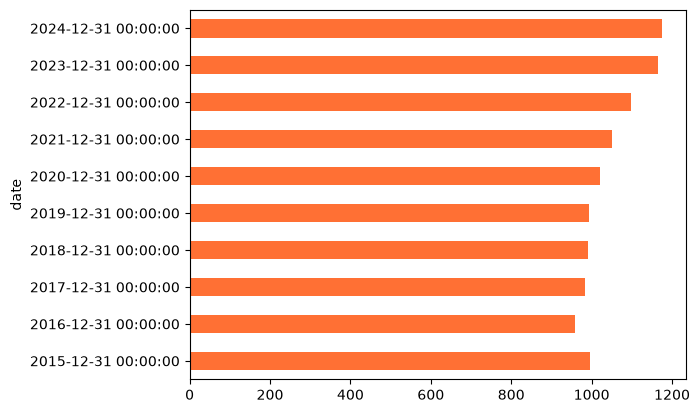

In [51]:
shootings_tally_year = police_data_over_time.resample('YE')['id'].count()
shootings_tally_year.plot(kind="barh", x="date", y="count", color="#ff7034")

shootings_tally_year.head()

KeyError: 'date'

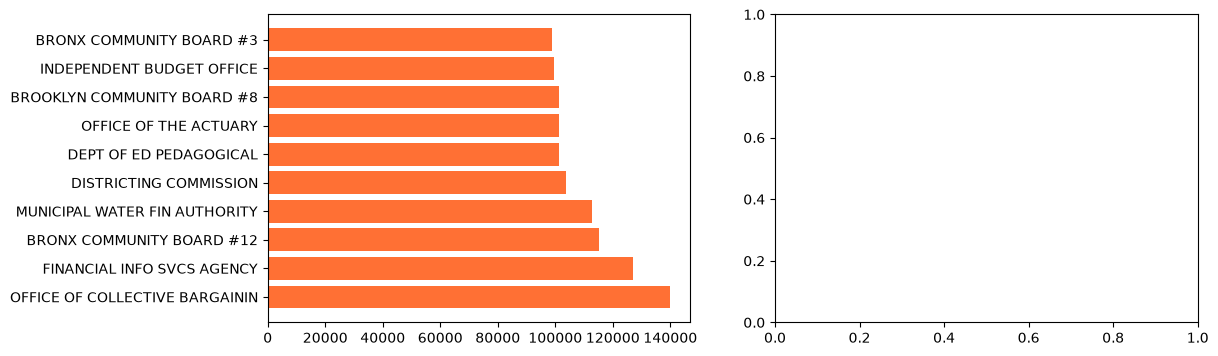

In [50]:
fig, ax = plt.subplots(1,2)
fig.set_size_inches(12,4)

ax[0].barh(top10_salary["Agency Name"], top10_salary["Base Salary"], color="#ff7034")
ax[1].barh(shootings_tally_year["date"], shootings_tally_year['count'], color="#ff7034")

### Part 2: Assignment 1

Come to class having made significant progress on your first assignment. Please come prepared to share your progress with your classmates and ask them/me any questions you might have for feedback. Part of classtime will be devoted to working on your original data analysis.